In [101]:
%pip install scikit-learn
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=5000, noise=0.1, random_state=0)
print(len(X))   # 500
print(len(y))   # 500

Note: you may need to restart the kernel to use updated packages.
5000
5000


n_samples = 500 Datenpunkte erzeugt, 250 pro Halbmond 
noise=0.1 = leichtes Rauschen, nicht direkt auf den Mondkurven 
random_state= Zufallswert fest

X: ein NumPy-Array der Form (500, 2) mit den x- und y-koordianten jedes Punktes 
y: ein Array der Form (500,) mit den Klassenlabels 0 oder 1, zu welchem Mond es gehört 

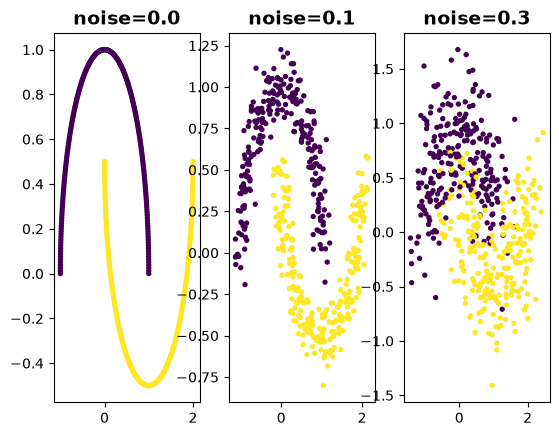

In [89]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

for i, n in enumerate([0.0, 0.1, 0.3]):
    X, y = make_moons(n_samples=500, noise=n, random_state=0)
    plt.subplot(1, 3, i + 1)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=8)
    plt.title(f"noise={n}")
plt.show()

Darstelung der Halbmonde 

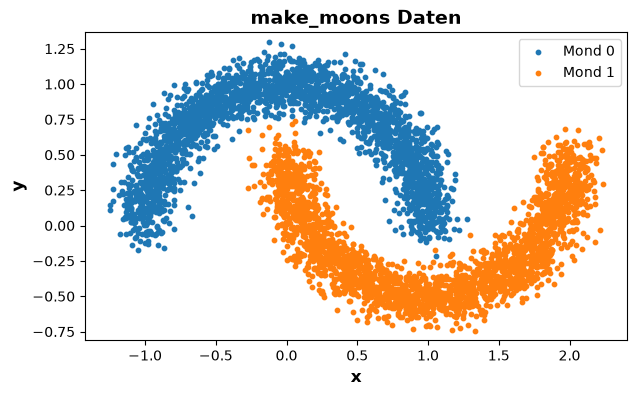

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color="tab:blue",   s=10, label="Mond 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], color="tab:orange", s=10, label="Mond 1")
plt.xlabel("x")
plt.ylabel("y")
plt.title("make_moons Daten")
plt.legend()
plt.axis("equal")
plt.show()


In [103]:

import torch
Xt = torch.from_numpy(X).float()   # Eingaben als float32
yt = torch.from_numpy(y).long()    # Labels als long

wandelt NumPy-Daten in PyTorch-tensoren um, damit ein neuronales Netz


Variable	Inhalt	        Form	    Typ	        Warum dieser Typ
Xt	        Koordinaten	    (500, 2)    float32   passt zu den Modellgewichten
yt	        Labels 0/1	    (500,)	    int64     wird von CrossEntropyLoss verlangt


In [104]:
import torch.nn as nn
from probly.method import dropout, ensemble

n_features = Xt.shape[1]
n_classes  = int(yt.max()) + 1

net = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, n_classes),   # gibt Logits aus, kein Softmax
)

mc  = dropout(net, p=0.2, predictor_type="logit_classifier")
ens = ensemble(net, num_members=5, predictor_type="logit_classifier")

torch.nn enthählt die Bausteine für neuronale Netzte: Schichten
dropout und ensemble, Tranformationen aus probly 

n_features = Xt.shape[1]          # 2  (x- und y-Koordinate)
n_classes  = int(yt.max()) + 1    # 2  (Labels 0 und 1, also max 1 + 1)



net = nn.Sequential(
    nn.Linear(n_features, 64),  # 2 Eingänge → 64 Neuronen
    nn.ReLU(),                  # Nichtlinearität
    nn.Linear(64, 64),          # versteckte Schicht
    nn.ReLU(),
    nn.Linear(64, n_classes),   # 64 → 2 Ausgänge
)



mc = dropout(net, p=0.2, predictor_type="logit_classifier")
probly kopiert net und setzt vor jede nn.Linear-Schicht eine nn.Dropout(p=0.2), außer vor die erste. Die Eingabe-Koordinaten selbst werden also nicht weggeworfen. Dein ursprüngliches net bleibt dabei unverändert.
Dropout schaltet bei jedem Durchlauf zufällig 20 % der Neuronen ab.
Der Trick dahinter (Monte-Carlo-Dropout, nach Gal & Ghahramani 2016): Dropout bleibt auch bei der Vorhersage aktiv. Schickt man denselben Punkt mehrmals durchs Netz, bekommt man jedes Mal ein etwas anderes Ergebnis.
Stimmen die Ergebnisse überein, ist das Modell sicher.
Schwanken sie stark, ist das Modell unsicher. Das passiert typischerweise zwischen den Monden oder weit weg von den Daten.


ens = ensemble(net, num_members=5, predictor_type="logit_classifier")
probly erzeugt 5 Kopien von net als nn.ModuleList. Jede Kopie bekommt neu zufällig initialisierte Gewichte (reset_params=True ist der Standard).
Jedes Mitglied wird einzeln trainiert und landet wegen des unterschiedlichen Startpunkts bei einer etwas anderen Lösung (Lakshminarayanan et al. 2017).
Bei der Vorhersage werden die 5 Ausgaben übereinandergestapelt. Wenn sich die Mitglieder uneinig sind, ist das wieder ein Zeichen für Unsicherheit.



	                            mc (Dropout)	ens (Ensemble)
Anzahl Netze	                1	            5
Woher kommt die Zufälligkeit?	zufällige Masken bei jedem Durchlauf unterschiedliche Startgewichte
Trainingsaufwand	            1 Netz	        5 Netze
Unsicherheitsschätzung	        gut	meist       besser

In [105]:
from probly.representer import representer

rep = representer(mc, num_samples=50)   # Dropout: 50 zufällige Durchläufe 

# rep = representer(ens)

   # Ensemble: jedes Mitglied genau einmal
s = rep.represent(Xt)    

xy = rep.represent(Xt[:43])    # Stichprobe von Vorhersagen
s.sample_mean().probabilities    

tensor([[0.4942, 0.5058],
        [0.5039, 0.4961],
        [0.4834, 0.5166],
        ...,
        [0.5194, 0.4806],
        [0.5100, 0.4900],
        [0.5149, 0.4851]], grad_fn=<DivBackward0>)

num_Sampler: wie oft durch das mc (Neutronen) Netz geschickt wird 
je mehr desto stabiler wird der Mittelwert 


Je höher der Wert desto Sicher ist es es sich das es dieser Mond ist. 

In [106]:
from probly.quantification import quantify

q = quantify(s)
q.total        # Gesamtunsicherheit
q.aleatoric    # Rauschen in den Daten, hoch an der Grenze zwischen den Monden
q.epistemic    # Unwissen des Modells, hoch abseits der Daten

tensor([0.0005, 0.0018, 0.0015,  ..., 0.0013, 0.0006, 0.0005],
       grad_fn=<SubBackward0>)

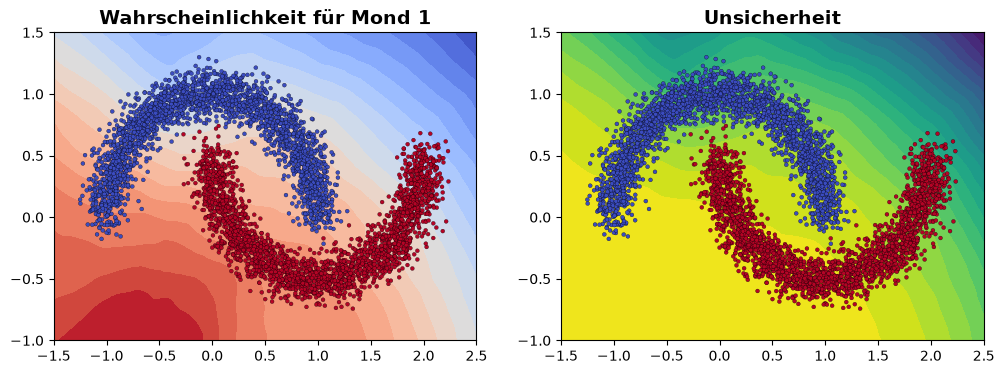

In [107]:
import numpy as np

xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

p = representer(ens).represent(grid).sample_mean().probabilities.detach()
unsicherheit = -(p * p.clamp_min(1e-12).log()).sum(dim=1)   # Entropie: 0 = sicher, 0.69 = völlig unsicher

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].contourf(xx, yy, p[:, 1].reshape(xx.shape), levels=20, cmap="coolwarm")
axes[0].set_title("Wahrscheinlichkeit für Mond 1")
axes[1].contourf(xx, yy, unsicherheit.reshape(xx.shape), levels=20, cmap="viridis")
axes[1].set_title("Unsicherheit")
for ax in axes:
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.2)
plt.show()
